# 03 · Receptiveness model: who pairs, and with what?

The engine needs two measured probabilities for every order at the moment its first item is rung:

| Symbol | Meaning | Model |
|---|---|---|
| **Q** | P(the order ends up with the other side of the pair anyway) | Part A, binary |
| **P(category)** | if it pairs, which category of the other side is added | Part B, multiclass |

Product choice *within* a category is taken from pooled sales shares, because notebook 02 finds no product-level
pairing signal beyond the category.

**Protocol.** Train on January-April, choose on May, refit on January-May, report on **June, which no choice ever
touched**. Every model is compared with simple baselines, as the brief requires.

**What we find**
- Part A: all models reach a June AUC of about 0.59-0.60. A one-line baseline (pairing rate by first-item category)
  ties logistic regression and beats gradient boosting. **We use the baseline**: same accuracy, nothing to maintain.
  Context (branch, hour, weekday, order type, loyalty) adds nothing measurable to *whether* an order pairs.
- Part B: knowing the first item's category improves *which* category is predicted by about 4.5% in log loss over
  global shares. Time of day is statistically significant (notebook 01) but adds almost nothing out of sample.
  Chosen on May: the simple table **"shares by first-item category"** (the logistic regression is within 0.4%).
- Neither model measures how people respond to a *suggestion*; Stories has never logged one. That gap is handled
  with explicit assumptions in notebook 05 and closed by the pilot.

In [1]:
# Setup: works in Google Colab, local Jupyter, and from the repo root
import os, sys, subprocess
REPO_URL = "https://github.com/mouhammed-soumaille/EECE-490-Hackathon.git"
if "google.colab" in sys.modules:
    if not os.path.exists("/content/EECE-490-Hackathon"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/EECE-490-Hackathon"], check=True)
    os.chdir("/content/EECE-490-Hackathon")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.join(os.getcwd(), "src"))

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score
from storiespair import data, models, viz
viz.style()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

lines = data.load_lines()
orders = data.build_orders(lines)
added = data.other_side_first_item(lines, orders)
tr, va, te = models.time_split(orders)
print(f"train Jan-Apr: {len(tr):,} orders | validate May: {len(va):,} | test June: {len(te):,}")
print("Features (all known when the first item is rung):", models.CAT_FEATURES + models.NUM_FEATURES)

train Jan-Apr: 20,542 orders | validate May: 6,439 | test June: 6,906
Features (all known when the first item is rung): ['first_side', 'first_category', 'first_product', 'branch', 'daypart', 'order_type', 'weekend', 'known_customer', 'hour_sin', 'hour_cos', 'first_price']


## Part A · Will the order pair anyway? (Q)

In [2]:
attach_table, attach_models = models.benchmark_attach(orders)
attach_table.round(4)

,model,valid_auc (May),test_auc (June),test_log_loss,test_brier
0,Base rate (always predict the average),0.5000,0.5000,0.5953,0.2027
1,Segment rate: first-item category,0.6010,0.5974,0.5832,0.1978
2,Segment rate: first product,0.5991,0.5952,0.5839,0.1980
3,Logistic regression (all context),0.6019,0.5930,0.5843,0.1982
4,Gradient boosting (all context),0.5999,0.5871,0.5855,0.1987


**Is the logistic regression really no better than the baseline?** A paired bootstrap on the June test set:

In [3]:
Xte, yte = models.trigger_features(te), te.paired.astype(int).values
p_seg = attach_models["Segment rate: first-item category"].predict_proba(Xte)[:, 1]
p_lr = attach_models["Logistic regression (all context)"].predict_proba(Xte)[:, 1]
p_hgb = attach_models["Gradient boosting (all context)"].predict_proba(Xte)[:, 1]
rng = np.random.default_rng(0)
diffs = {"LR - baseline": [], "GBM - baseline": []}
for _ in range(500):
    i = rng.integers(0, len(yte), len(yte))
    base = roc_auc_score(yte[i], p_seg[i])
    diffs["LR - baseline"].append(roc_auc_score(yte[i], p_lr[i]) - base)
    diffs["GBM - baseline"].append(roc_auc_score(yte[i], p_hgb[i]) - base)
pd.DataFrame({k: {"mean AUC difference": np.mean(v), "95% CI low": np.percentile(v, 2.5),
                  "95% CI high": np.percentile(v, 97.5)} for k, v in diffs.items()}).T.round(4)

,mean AUC difference,95% CI low,95% CI high
LR - baseline,-0.0043,-0.0091,0.0006
GBM - baseline,-0.0103,-0.0165,-0.0046


Both confidence intervals straddle zero or sit below it. Decision: **the engine uses the segment-rate baseline for Q.**
Rejected: gradient boosting (more complex, no gain, slightly worse on June).

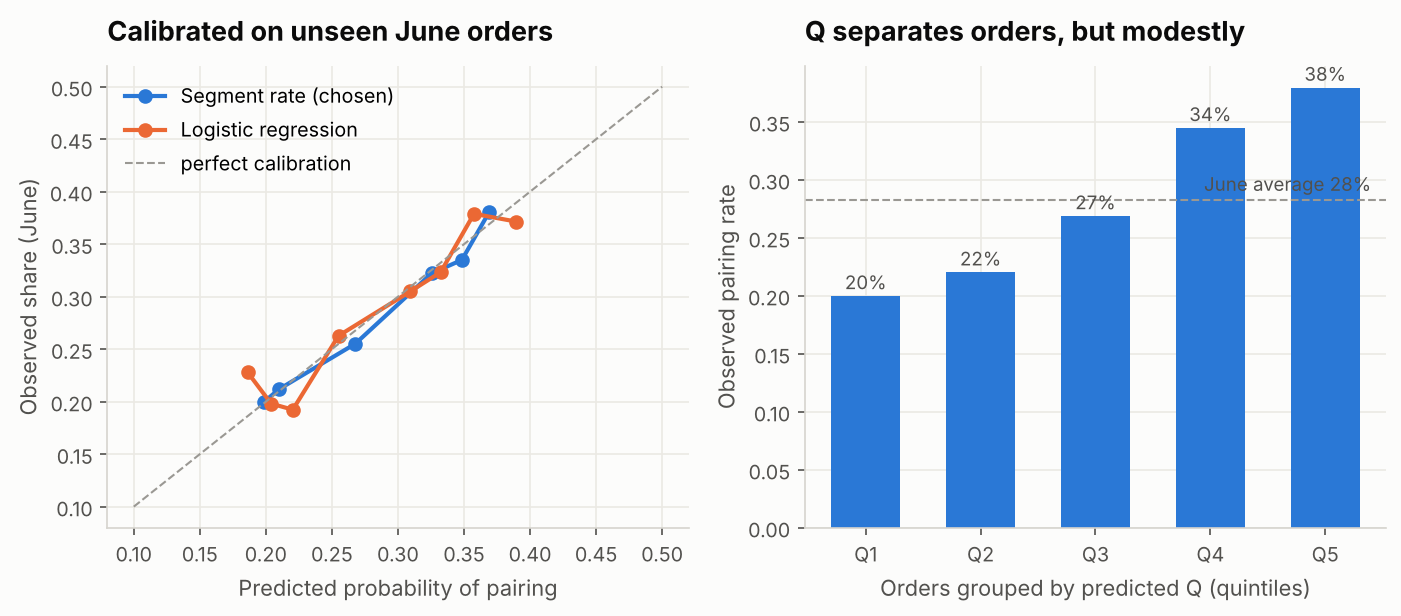

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
for p, name, c in [(p_seg, "Segment rate (chosen)", viz.BLUE), (p_lr, "Logistic regression", viz.ORANGE)]:
    fy, fx = calibration_curve(yte, p, n_bins=8, strategy="quantile")
    ax.plot(fx, fy, marker="o", color=c, label=name, markersize=6)
ax.plot([0.1, 0.5], [0.1, 0.5], color=viz.GREY, lw=1, ls="--", label="perfect calibration")
ax.set_xlabel("Predicted probability of pairing"); ax.set_ylabel("Observed share (June)")
ax.set_title("Calibrated on unseen June orders"); ax.legend()
ax = axes[1]
dec = pd.qcut(pd.Series(p_seg).rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
lift = pd.Series(yte).groupby(dec.values).mean()
ax.bar(lift.index, lift.values, color=viz.BLUE, width=0.6)
ax.axhline(yte.mean(), color=viz.GREY, lw=1, ls="--")
ax.text(4.4, yte.mean() + 0.008, f"June average {yte.mean():.0%}", ha="right", color=viz.INK_2, fontsize=9)
for x, v in zip(range(5), lift.values):
    ax.text(x, v + 0.006, f"{v:.0%}", ha="center", fontsize=9, color=viz.INK_2)
ax.set_xlabel("Orders grouped by predicted Q (quintiles)"); ax.set_ylabel("Observed pairing rate")
ax.set_title("Q separates orders, but modestly")
viz.savefig(fig, "03_attach_calibration_lift")
plt.show()

## Part B · If it pairs, which category is added?

In [5]:
choice_tables = {}
for side, label in [("drink", "first item is a drink -> which FOOD category"), ("food", "first item is a food -> which DRINK category")]:
    t, _ = models.benchmark_choice(orders, added, side)
    base = t.loc[t.model == "Global category shares", "test_log_loss (June)"].iloc[0]
    t["log_loss_improvement_vs_global"] = (base - t["test_log_loss (June)"]) / base
    choice_tables[side] = t
    print(f"\n{label}")
    print(t.round(4).to_string(index=False))


first item is a drink -> which FOOD category
                                  model  valid_log_loss (May)  test_log_loss (June)  test_top1_acc  test_top2_acc  log_loss_improvement_vs_global
                 Global category shares                1.2002                1.1861          0.613         0.7427                          0.0000
                      Shares by daypart                1.2031                1.1835          0.613         0.7395                          0.0022
          Shares by first-item category                1.1487                1.1315          0.613         0.7280                          0.0461
Shares by first-item category x daypart                1.1593                1.1346          0.613         0.7395                          0.0434
        Multinomial logistic regression                1.1536                1.1287          0.613         0.7521                          0.0484

first item is a food -> which DRINK category
                                

Top-1 accuracy barely moves in the drink-first case because Bakery is the most likely food almost everywhere. The
value is in the **full probability distribution** (log loss), which is what the engine multiplies by profit.

**Selection rule** (decided before looking at June): best May log loss, and if models are within 0.5% of each
other, take the simplest. Drink-first: "shares by first-item category" is best on May outright. Food-first: it ties
the first-item x daypart table (1.2642 vs 1.2640). So the engine uses **shares by first-item category** in both
directions. On June the logistic regression edges ahead by under 0.3%, which we report but do not chase.

A useful lesson for Stories' data team: daypart is *statistically significant* for what gets added (p < 1e-30 in
notebook 01) yet does not improve prediction on unseen months. Significance is not usefulness.

In [6]:
pm = models.PairModels.fit(orders, lines, added)  # chosen models, refit on Jan-May
examples = pd.DataFrame([
    {"first_side": "drink", "first_category": "Matcha & Tea", "first_product": "Iced Matcha", "daypart": "Morning", "hour": 9},
    {"first_side": "drink", "first_category": "Cold Drinks", "first_product": "Lemonade", "daypart": "Midday", "hour": 13},
    {"first_side": "drink", "first_category": "Hot Coffee", "first_product": "Cappuccino", "daypart": "Evening", "hour": 21},
]).assign(branch="Harbour", order_type="Dine-in", weekend=False, known_customer=False, first_price=5.0)
P = pm.category_probs(models.trigger_features(examples), "drink")
P.index = [r.first_product for r in examples.itertuples()]
P.round(3)

,Bakery,Breakfast,Desserts,Sandwiches,Meals
Iced Matcha,0.779,0.048,0.069,0.073,0.031
Lemonade,0.447,0.139,0.173,0.174,0.068
Cappuccino,0.469,0.140,0.150,0.159,0.081


## Item level: share of each product inside its category

Pooled January-May sales. Notebook 02 shows these shares do not depend on which drink was bought.

In [7]:
share = pm.item_share.rename("share_within_category").reset_index()
share.sort_values(["category", "share_within_category"], ascending=[True, False]).round(3).head(12)

,category,product,share_within_category
3,Bakery,Butter Croissant,0.192
4,Bakery,Chocolate Cookie,0.147
5,Bakery,Chocolate Croissant,0.131
6,Bakery,Cinnamon Roll,0.128
7,Bakery,Pistachio Cookie,0.114
1,Bakery,Banana Bread,0.107
0,Bakery,Almond Croissant,0.100
2,Bakery,Blueberry Muffin,0.080
9,Breakfast,Egg Sandwich,0.399
8,Breakfast,Avocado Toast,0.364


In [8]:
viz.savetable(attach_table, "03_attach_model_benchmark")
_ = viz.savetable(pd.concat([t.assign(direction=s) for s, t in choice_tables.items()]), "03_category_model_benchmark")